# 베이즈 갱신과 수락·기각 표본추출

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## 상자 추론

상자 A·B의 빨간 공 비율은 각각 0.1·0.8이고 사전확률은 각각 0.5이다. 복원추출 10회에서 빨간 공이 2개 또는 4개 나왔을 때 상자별 사후확률을 구하시오.

In [2]:
from scipy.stats import binom
for red in [2,4]:
    likelihood = binom.pmf(red, 10, [0.1,0.8])
    posterior = likelihood / likelihood.sum()
    pvalue = binom.sf(red-1, 10, 0.1)
    print(red, 'posterior A/B:', posterior, 'A 기준 상측 p값:', pvalue)
assert np.isclose(binom.pmf(4,10,.1)/(binom.pmf(4,10,.1)+binom.pmf(4,10,.8)), .6696711757404689)

2 posterior A/B: [0.99962 0.00038] A 기준 상측 p값: 0.2639010709
4 posterior A/B: [0.66967 0.33033] A 기준 상측 p값: 0.0127951984


사후확률과 p값은 서로 다른 질문의 답. 빨간 공 2개만 관측한 경우와, 10개 중 빨간 공 2개를 관측한 경우를 구분.

## 수락·기각 표본추출

목표 함수는 `f(x)=0.3 exp(-0.2x²)+0.7 exp(-0.2(x−10)²)`. 구간 `[-7,17)`에서 균등 제안하고 높이 H=0.71 아래의 점 중 f 아래만 수락. 목표는 이 구간으로 제한한 밀도.

후보 900개를 생성하시오. 수락 비율과 표본 모양을 확인하시오.

수락 수: 196 수락 비율: 0.21777777777777776
이론적 평균 수락 비율: 0.23258851988391993


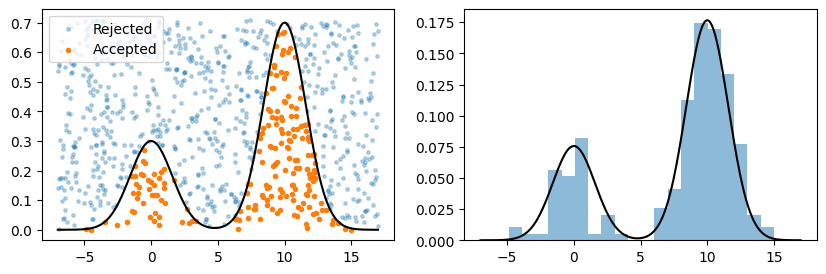

In [3]:
from scipy.integrate import quad
def f(x):
    return 0.3*np.exp(-0.2*x*x) + 0.7*np.exp(-0.2*(x-10)**2)
rng = np.random.default_rng(42)
H = 0.71
candidate = rng.uniform(-7, 17, 900)
height = rng.uniform(0, H, 900)
keep = height < f(candidate)
sample = candidate[keep]
area = quad(f, -7, 17)[0]
print('수락 수:', keep.sum(), '수락 비율:', keep.mean())
print('이론적 평균 수락 비율:', area/(24*H))
assert H > 0.7 + 0.3*np.exp(-5)
fig, ax = plt.subplots(1,2,figsize=(10,3))
grid = np.linspace(-7,17,500)
ax[0].scatter(candidate[~keep],height[~keep],s=6,alpha=.3,label='Rejected')
ax[0].scatter(sample,height[keep],s=9,label='Accepted')
ax[0].plot(grid,f(grid),'k'); ax[0].legend()
ax[1].hist(sample,bins=20,density=True,alpha=.5)
ax[1].plot(grid,f(grid)/area,'k')
plt.show()

Excel: F9로 다시 추출할 때 수락 수 변화. 고정된 수락 개수가 정답은 아님.

H를 1.0으로 바꿔 수락률을 비교하시오. H를 0.5로 두면 목표 분포가 왜곡되는 이유를 설명하시오. 난수 시드를 바꿔도 유지되는 특징을 찾으시오.